# Fitting the redshift with a photo-z prior

This notebook fits the real Fairall 9 photometry (from the VizieR tutorial, stored in `data/fairall9_vizier_photometry.ecsv`) with the redshift free, under a deliberately misleading bimodal photo-z prior: a broad peak at $z \approx 0.5$ and a narrow one at the true redshift. It shows

- a fast profile-likelihood redshift scan with MAP fits at fixed redshift;
- a full posterior fit with the redshift sampled by NUTS.

You need the DSPS SSP file `tempdata.h5` in the repository root.

In [1]:
import copy

import numpy as np
import matplotlib.pyplot as plt
import numpyro.distributions as dist
from astropy.table import Table

from jaxsedfit import (
    AGNConfig,
    FilterSet,
    FitConfig,
    GalaxyConfig,
    InferenceConfig,
    JAXSEDFit,
    LikelihoodConfig,
    Observation,
    PhotometryData,
    PriorConfig,
    RedshiftPriorConfig,
    load_filter_curves,
)

## 1. Photometry and the photo-z prior

`RedshiftPriorConfig` takes any tabulated $p(z)$, for example the PDF from a photo-z code.

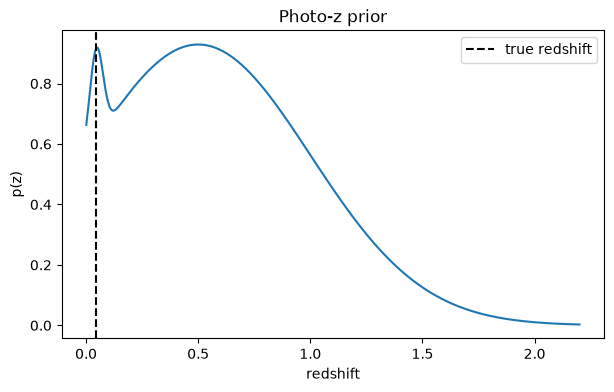

In [2]:
phot = Table.read("data/fairall9_vizier_photometry.ecsv")
true_z = 0.04587

z_grid = np.linspace(0.001, 2.2, 800)  # the prior grid must be strictly positive
pdf = 2.0 * np.exp(-0.5 * ((z_grid - 0.5) / 0.5) ** 2) + 0.65 * np.exp(-0.5 * ((z_grid - true_z) / 0.03) ** 2)
pdf /= np.trapezoid(pdf, z_grid)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(z_grid, pdf)
ax.axvline(true_z, color="k", ls="--", label="true redshift")
ax.set(xlabel="redshift", ylabel="p(z)", title="Photo-z prior")
ax.legend();

## 2. Configure the fit

`redshift_mode="fit"` makes the redshift a free parameter; `redshift` is then only the starting value.

In [3]:
config = FitConfig(
    observation=Observation(object_id="Fairall 9 photo-z", redshift=true_z, redshift_mode="fit", redshift_err=0.5),
    photometry=PhotometryData(
        filter_names=list(phot["grahsp_filter"]),
        fluxes=list(phot["flux_mjy"]),
        errors=list(phot["err_mjy"]),
        psf_fwhm_arcsec=list(phot["psf_fwhm_arcsec"]),
    ),
    filters=FilterSet(curves=load_filter_curves(list(phot["grahsp_filter"]))),
    galaxy=GalaxyConfig(dsps_ssp_fn="../tempdata.h5"),
    agn=AGNConfig(agn_type=1),
    likelihood=LikelihoodConfig(use_host_capture_model=True),
    inference=InferenceConfig(map_steps=400, learning_rate=5e-3, seed=0),
    prior_config=PriorConfig(
        redshift=RedshiftPriorConfig(z_grid=z_grid, pdf=pdf),
        stellar_mass=dist.Normal(10.5, 1.0),
        host={"ebv_gal": dist.HalfNormal(0.15)},
        agn={"ebv_agn": dist.HalfNormal(0.15)},
    ),
)

## 3. Profile-likelihood scan

A quick way to see where the photometry wants the redshift: fit the MAP at a grid of fixed redshifts and weight $\exp(-\mathrm{loss})$ by the prior. A coarser model grid (`n_wave`, `sfh_n_steps`, no energy balance) keeps each fit fast.

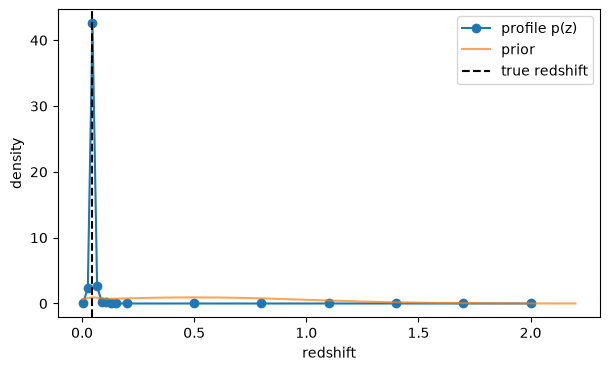

In [4]:
def map_loss(z):
    scan = copy.deepcopy(config)
    scan.observation.redshift = float(z)
    scan.observation.redshift_mode = "fixed"
    scan.galaxy.n_wave = 384
    scan.galaxy.sfh_n_steps = 24
    scan.galaxy.use_energy_balance = False
    scan.inference.method = "optax"
    scan.inference.map_steps = 120
    fitter = JAXSEDFit(scan)
    fitter.fit(progress_bar=False)
    return fitter.map_result["losses"][-1]


z_scan = np.concatenate([np.linspace(0.005, 0.15, 8), np.linspace(0.2, 2.0, 7)])
loss = np.array([map_loss(z) for z in z_scan])
profile = np.exp(-(loss - loss.min())) * np.interp(z_scan, z_grid, pdf)
profile /= np.trapezoid(profile, z_scan)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(z_scan, profile, "o-", label="profile p(z)")
ax.plot(z_grid, pdf, alpha=0.7, label="prior")
ax.axvline(true_z, color="k", ls="--", label="true redshift")
ax.set(xlabel="redshift", ylabel="density")
ax.legend();

## 4. Posterior with a free redshift

`method="optax+nuts"` finds the MAP, which starts NUTS in the dominant redshift mode. NUTS explores one mode well but rarely jumps between well-separated modes; the profile scan above shows whether a second mode matters. Nested sampling (`method="ns"`) is designed for multimodal posteriors.


                                          mean       std    median      5.0%     95.0%     n_eff     r_hat
                broad_lines_strength      1.67      2.36      0.75      0.30      4.58    104.96      1.03
                            cool_lam     17.42      5.41     16.57     10.15     25.20     50.45      0.99
                          cool_width      0.56      0.08      0.58      0.44      0.65     10.58      1.36
                          dust_alpha      1.77      0.57      1.70      1.00      2.75    119.32      1.01
                             ebv_agn      0.06      0.06      0.03      0.00      0.15     72.39      1.00
                             ebv_gal      0.04      0.03      0.03      0.00      0.08     29.75      1.02
                                fcov      0.29      0.15      0.27      0.06      0.48     20.20      1.09
                           feii_norm      7.20      7.17      4.42      0.64     17.51    180.83      1.00
                             hot_lam

/Users/colinburke/research/jaxsedfit-tutorials/src/jaxsedfit/results.py:30: RuntimeWarning: All-NaN slice encountered
  out[key] = np.nanmedian(arr, axis=0)


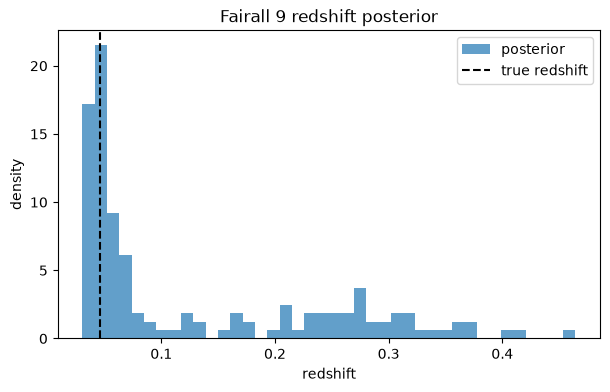

In [5]:
config.inference.method = "optax+nuts"
config.inference.num_warmup = 150
config.inference.num_samples = 150

fitter = JAXSEDFit(config)
result = fitter.fit(progress_bar=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(result.samples["redshift_fit"], bins=40, density=True, alpha=0.7, label="posterior")
ax.axvline(true_z, color="k", ls="--", label="true redshift")
ax.set(xlabel="redshift", ylabel="density", title="Fairall 9 redshift posterior")
ax.legend();